# Parte 3
## Exploración y características relevantes

Este notebook consume exclusivamente `df_master_pre_modelado.csv`, generado por `EDA_corregido_Gran_Concepcion.ipynb`.

**Pregunta operativa:** ¿Qué tan bien se pueden estimar las emisiones (toneladas) de un grupo de vehículos en una comuna del Gran Concepción a partir de la comuna, el grupo vehicular y la composición de los registros de permisos de circulación disponibles?

**No es un pronóstico temporal.** `año` se utiliza para integrar y auditar cobertura, pero no será predictor. La unidad de análisis es una fila por año–comuna–grupo vehicular y contaminante.

**Precaución:** las variables de permisos son conteos de registros administrativos, no necesariamente vehículos únicos. Solo deben utilizarse si están disponibles en el momento de la estimación. No se permite usar `registros_ruea` como predictor porque procede de la misma fuente y del proceso de construcción del objetivo.

### 3.1 Carga, selección del contaminante y control de calidad

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, chi2_contingency
from sklearn.feature_selection import mutual_info_regression

# Carpetas de salida (relativas a la carpeta de este notebook)
CARPETA_FIGURAS = Path("figs")
SALIDAS = Path("outputs")
CARPETA_FIGURAS.mkdir(exist_ok=True)
SALIDAS.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# El dataset se lee desde el repositorio de GitHub (versión "raw" del archivo del enlace /blob/).
URL_DATASET = ("https://raw.githubusercontent.com/nicolasvergal01-pixel/"
               "Proyecto-Taller-ciencia-de-datos-/main/data/raw/df_master_pre_modelado.csv")
RUTA_LOCAL = Path("df_master_pre_modelado.csv")   # respaldo si no hay internet o el repo no abre

def leer_dataset():
    try:
        d = pd.read_csv(URL_DATASET)
        print("Dataset leído desde GitHub:", URL_DATASET)
        return d
    except Exception as e:
        print(f"No pude leer el dataset desde GitHub ({type(e).__name__}: {e}).")
        if RUTA_LOCAL.exists():
            print("Uso el archivo local:", RUTA_LOCAL.resolve())
            return pd.read_csv(RUTA_LOCAL)
        raise FileNotFoundError(
            "No se pudo leer df_master_pre_modelado.csv ni desde GitHub ni desde la carpeta local. "
            "Revisa que el repositorio sea público y que el archivo esté en data/raw/, "
            "o copia el CSV junto a este notebook."
        )

df = leer_dataset()
df.columns = df.columns.str.strip()

OBJETIVO = "emisiones_agregadas_toneladas"
if OBJETIVO not in df:
    raise ValueError(f"No está el objetivo {OBJETIVO}. Columnas: {df.columns.tolist()}")

# Seleccionar contaminante
COL_CONT = next((c for c in df.columns if "contamin" in c or "sustancia" in c), None)
CONTAMINANTE_ELEGIDO = "Dióxido de carbono (CO2)"
if COL_CONT:
    valores = df[COL_CONT].dropna().astype(str).unique().tolist()
    print("Contaminantes disponibles:", valores)
    if len(valores) > 1 and CONTAMINANTE_ELEGIDO is None:
        raise ValueError("Hay más de un contaminante. Define CONTAMINANTE_ELEGIDO antes de modelar.")
    if CONTAMINANTE_ELEGIDO is not None:
        df = df[df[COL_CONT].astype(str) == str(CONTAMINANTE_ELEGIDO)].copy()

claves = ["año", "comuna_norm", "grupo_vehiculo"]
faltan = [c for c in claves if c not in df]
if faltan:
    raise ValueError(f"Faltan columnas de la clave: {faltan}")
df[OBJETIVO] = pd.to_numeric(df[OBJETIVO], errors="coerce")
df = df.dropna(subset=[OBJETIVO, "comuna_norm", "grupo_vehiculo"]).copy()

# Control: el CSV antiguo (conversión de toneladas sin corregir) tenía un máximo ~1e8 veces la mediana.
if df[OBJETIVO].max() > 1e4 * max(df[OBJETIVO].median(), 1e-9):
    raise ValueError(
        "El objetivo tiene valores absurdamente grandes: este df_master_pre_modelado.csv parece ser "
        "el antiguo. Sube a GitHub el CSV regenerado por el EDA corregido (o usa el local)."
    )

print("Filas:", len(df), "| columnas:", len(df.columns))
print("Duplicados por clave:", df.duplicated(claves).sum())
if df.duplicated(claves).any():
    raise ValueError("Hay duplicados año-comuna-grupo; revisa la agregación en el EDA.")
display(df.head())

Dataset leído desde GitHub: https://raw.githubusercontent.com/nicolasvergal01-pixel/Proyecto-Taller-ciencia-de-datos-/main/data/raw/df_master_pre_modelado.csv
Contaminantes disponibles: ['Compuestos Orgánicos Volátiles', 'Dibenzoparadioxinas policloradas y furanos (PCDD/F)', 'Dióxido de azufre (SO2)', 'Dióxido de carbono (CO2)', 'MP10', 'MP2,5', 'Material particulado', 'Mercurio', 'Metano (CH4)', 'Monóxido de carbono', 'NOx', 'Nitrógeno amoniacal (o NH3)', 'Oxido Nitroso']
Filas: 110 | columnas: 15
Duplicados por clave: 0


,año,comuna_norm,grupo_vehiculo,contaminantes,emisiones_agregadas_toneladas,registros_ruea,registros_permiso,permisos_combustible_bencina,permisos_combustible_diesel,permisos_combustible_electrico,permisos_combustible_gas,registros_catalitico,permisos_cataliticos,permisos_no_cataliticos,tiene_registro_permiso
3,2022,chiguayante,Buses,Dióxido de carbono (CO2),17.002684,8,663.0,224.0,439.0,0.0,0.0,663.0,663.0,0.0,True
16,2022,chiguayante,Camiones,Dióxido de carbono (CO2),29.061302,14,441.0,64.0,377.0,0.0,0.0,441.0,419.0,22.0,True
29,2022,chiguayante,Comerciales livianos,Dióxido de carbono (CO2),29.383067,15,6663.0,2380.0,4283.0,0.0,0.0,6663.0,6534.0,129.0,True
42,2022,chiguayante,Livianos pasajeros,Dióxido de carbono (CO2),96.532757,76,26591.0,24128.0,2401.0,62.0,0.0,26591.0,26332.0,259.0,True
55,2022,chiguayante,Motocicletas,Dióxido de carbono (CO2),14.076541,12,751.0,747.0,0.0,4.0,0.0,751.0,745.0,6.0,True


In [5]:
# Calidad del objetivo y disponibilidad de columnas
n_total = len(df)
n_nulos_y = int(df[OBJETIVO].isna().sum())
print(f"Objetivo: n={n_total-n_nulos_y}/{n_total}; nulos={n_nulos_y} ({n_nulos_y/max(n_total,1):.1%})")
print(f"Mediana={df[OBJETIVO].median():.4g} t; media={df[OBJETIVO].mean():.4g} t; "
      f"mín={df[OBJETIVO].min():.4g} t; máx={df[OBJETIVO].max():.4g} t")
display(df.isna().sum().to_frame("n_nulos").assign(pct=lambda x: 100*x.n_nulos/max(len(df),1)))
display(df.groupby("año")[OBJETIVO].agg(n="count", media="mean", mediana="median"))

Objetivo: n=110/110; nulos=0 (0.0%)
Mediana=41.56 t; media=47.41 t; mín=0 t; máx=155.2 t


,n_nulos,pct
año,0,0.000000
comuna_norm,0,0.000000
grupo_vehiculo,0,0.000000
contaminantes,0,0.000000
emisiones_agregadas_toneladas,0,0.000000
registros_ruea,0,0.000000
registros_permiso,1,0.909091
permisos_combustible_bencina,1,0.909091
permisos_combustible_diesel,1,0.909091
permisos_combustible_electrico,1,0.909091


,n,media,mediana
año,,,
2022,50,45.697081,31.742944
2023,60,48.840504,44.030520


### 3.2 Bitácora de EDA
Cada hallazgo queda calculado con cifra y `n`, figura guardada, celda generadora, vínculo con la pregunta y decisión. Las figuras declaran unidad, escala y celda.

C:\Users\joaqu\AppData\Local\Temp\ipykernel_17364\2869980257.py:11: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(CARPETA_FIGURAS / "01_objetivo.png", dpi=160); plt.show()
C:\Users\joaqu\AppData\Roaming\Python\Python315\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


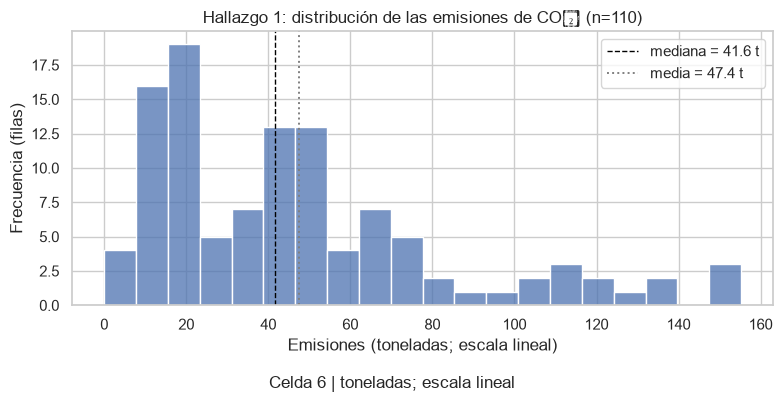

In [6]:
# Hallazgo 1 — distribución del objetivo (celda 6)
y = df[OBJETIVO].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(y, bins=20, ax=ax)
ax.axvline(y.median(), color="black", ls="--", lw=1, label=f"mediana = {y.median():.3g} t")
ax.axvline(y.mean(), color="gray", ls=":", lw=1.4, label=f"media = {y.mean():.3g} t")
ax.legend()
ax.set(title=f"Hallazgo 1: distribución de las emisiones de CO₂ (n={len(y)})",
       xlabel="Emisiones (toneladas; escala lineal)", ylabel="Frecuencia (filas)")
fig.text(0.5, 0.01, "Celda 6 | toneladas; escala lineal", ha="center")
fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(CARPETA_FIGURAS / "01_objetivo.png", dpi=160); plt.show()


In [7]:
n_ceros = int((y == 0).sum())
h1_resultado = (f"Objetivo: n={len(y)}, mediana={y.median():.4g} t, media={y.mean():.4g} t, "
                f"máx={y.max():.4g} t; nulos={df[OBJETIVO].isna().sum()}; filas con 0 t={n_ceros}")
h1_decision = (
    "Definir MAE en toneladas como métrica principal. La distribución es moderadamente asimétrica "
    f"(media {y.mean():.3g} t vs mediana {y.median():.3g} t; máximo {y.max():.3g} t = {y.max()/y.median():.1f} veces la mediana), "
    "por lo que no se transforma el objetivo."
)
print(f"""
HALLAZGO 1
============================================================
• Resultado : {h1_resultado}
• Figura    : figs/01_objetivo.png
• Pregunta  : Distribución y escala del resultado
• Decisión  : {h1_decision}
""")



HALLAZGO 1
• Resultado : Objetivo: n=110, mediana=41.56 t, media=47.41 t, máx=155.2 t; nulos=0; filas con 0 t=4
• Figura    : figs/01_objetivo.png
• Pregunta  : Distribución y escala del resultado
• Decisión  : Definir MAE en toneladas como métrica principal. La distribución es moderadamente asimétrica (media 47.4 t vs mediana 41.6 t; máximo 155 t = 3.7 veces la mediana), por lo que no se transforma el objetivo.



,n,media,mediana,total
grupo_vehiculo,,,,
Motocicletas,20,16.410474,16.162017,328.209477
Buses,20,20.908795,20.298995,418.175900
Camiones,20,37.864664,42.614811,757.293283
Taxis,10,46.758084,52.859367,467.580837
Comerciales livianos,20,51.736815,50.972789,1034.736295
Livianos pasajeros,20,110.464427,113.207783,2209.288531


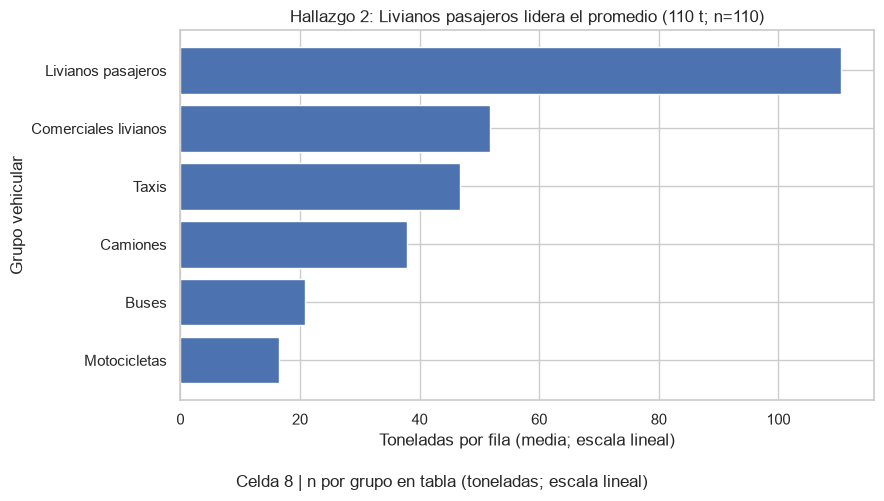

In [8]:
# Hallazgo 2 — emisiones por grupo vehicular (celda 8)
g = df.groupby("grupo_vehiculo")[OBJETIVO].agg(
    n="count", media="mean", mediana="median", total="sum"
).sort_values("media")
display(g)

n_total_h2 = int(g.n.sum())
top_grupo, top_media = g.media.idxmax(), g.media.max()
min_grupo, min_media = g.media.idxmin(), g.media.min()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(g.index, g["media"])
ax.set(title=f"Hallazgo 2: {top_grupo} lidera el promedio ({top_media:.3g} t; n={n_total_h2})",
       xlabel="Toneladas por fila (media; escala lineal)", ylabel="Grupo vehicular")
fig.text(0.5, 0.01, "Celda 8 | n por grupo en tabla (toneladas; escala lineal)", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "02_grupo_vehicular.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos
h2_resultado = (f"{len(g)} grupos; mayor promedio={top_grupo} ({top_media:.4g} t), "
                f"menor={min_grupo} ({min_media:.4g} t), n={n_total_h2}")
h2_decision = (
    f"Mantener grupo_vehiculo como candidata categórica: las medias van de {min_media:.3g} t ({min_grupo}) "
    f"a {top_media:.3g} t ({top_grupo}), unas {top_media / min_media:.1f} veces. "
    f"El n por grupo va de {int(g.n.min())} a {int(g.n.max())} filas (cobertura distinta entre años; ver limitaciones)."
)

hallazgo_2 = [
    "H2",
    h2_resultado,
    "figs/02_grupo_vehicular.png",
    "8",
    "Tipo de vehículo",
    h2_decision
]


In [9]:
print(f"""
HALLAZGO 2
============================================================
• Resultado : {h2_resultado}
• Figura    : figs/02_grupo_vehicular.png
• Pregunta  : Tipo de vehículo
• Decisión  : {h2_decision}
""")


HALLAZGO 2
• Resultado : 6 grupos; mayor promedio=Livianos pasajeros (110.5 t), menor=Motocicletas (16.41 t), n=110
• Figura    : figs/02_grupo_vehicular.png
• Pregunta  : Tipo de vehículo
• Decisión  : Mantener grupo_vehiculo como candidata categórica: las medias van de 16.4 t (Motocicletas) a 110 t (Livianos pasajeros), unas 6.7 veces. El n por grupo va de 10 a 20 filas (cobertura distinta entre años; ver limitaciones).



,n,media,mediana,total
comuna_norm,,,,
hualqui,11,30.476726,16.779665,335.243989
chiguayante,11,36.395750,29.061302,400.353246
lota,11,43.567456,35.315429,479.242011
tome,11,44.688341,38.904626,491.571755
hualpen,11,47.879444,37.905702,526.673882
penco,11,50.117088,43.977681,551.287972
san pedro de la paz,11,52.875975,44.834456,581.635726
coronel,11,55.935039,48.498762,615.285432
talcahuano,11,56.075018,48.090057,616.825203


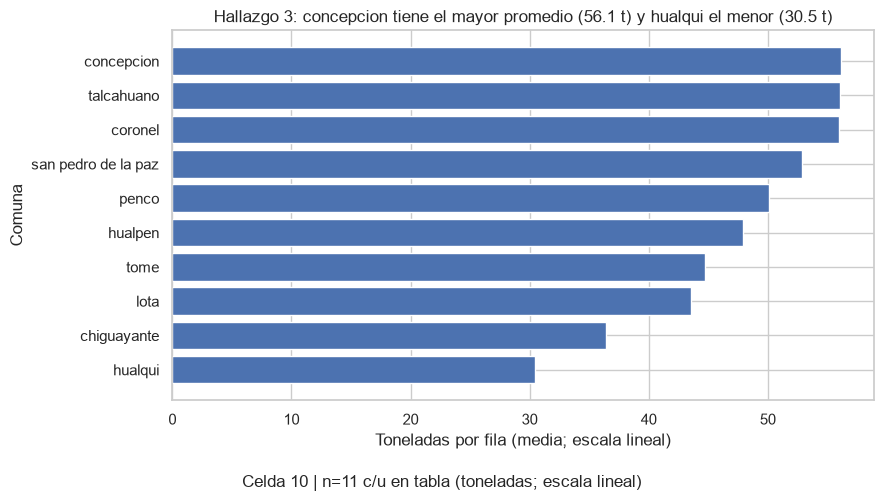

In [10]:
# Hallazgo 3 — diferencias territoriales (celda 10)
c = df.groupby("comuna_norm")[OBJETIVO].agg(
    n="count", media="mean", mediana="median", total="sum"
).sort_values("media")
display(c)

n_total_h3 = int(c.n.sum())
top_comuna = c.media.idxmax()
top_media_c = c.media.max()
min_comuna = c.media.idxmin()
min_media_c = c.media.min()
n_txt = f"n={int(c.n.iloc[0])} c/u" if c.n.nunique() == 1 else f"n={int(c.n.min())} a {int(c.n.max())} por comuna"

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(c.index, c["media"])
ax.set(title=f"Hallazgo 3: {top_comuna} tiene el mayor promedio ({top_media_c:.3g} t) y {min_comuna} el menor ({min_media_c:.3g} t)",
       xlabel="Toneladas por fila (media; escala lineal)", ylabel="Comuna")
fig.text(0.5, 0.01, f"Celda 10 | {n_txt} en tabla (toneladas; escala lineal)", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "03_comuna.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos
h3_resultado = (
    f"{len(c)} comunas ({n_txt}, n={n_total_h3}); mayor promedio={top_comuna} "
    f"({top_media_c:.4g} t) vs menor={min_comuna} ({min_media_c:.4g} t)."
)
h3_decision = (
    "Evaluar la diferencia territorial sin interpretarla como causal; "
    "verificar si responde a la mezcla de tipos de vehículo por comuna. "
    "La comuna se usa como variable de agrupación en la validación, no como predictor."
)

hallazgo_3 = [
    "H3",
    h3_resultado,
    "figs/03_comuna.png",
    "10",
    "Territorio",
    h3_decision
]


In [11]:
print(f"""
HALLAZGO 3
============================================================
• Resultado : {h3_resultado}
• Figura    : figs/03_comuna.png
• Pregunta  : Territorio
• Decisión  : {h3_decision}""")


HALLAZGO 3
• Resultado : 10 comunas (n=11 c/u, n=110); mayor promedio=concepcion (56.11 t) vs menor=hualqui (30.48 t).
• Figura    : figs/03_comuna.png
• Pregunta  : Territorio
• Decisión  : Evaluar la diferencia territorial sin interpretarla como causal; verificar si responde a la mezcla de tipos de vehículo por comuna. La comuna se usa como variable de agrupación en la validación, no como predictor.


,variable,spearman,n,valores_distintos
0,registros_permiso,0.649525,109,108
1,proporcion_combustible_bencina,0.106248,109,102
2,proporcion_combustible_diesel,-0.086654,109,95
3,proporcion_combustible_electrico,0.174471,109,53
4,proporcion_combustible_gas,0.131107,109,10
5,tasa_no_cataliticos,0.210333,109,91


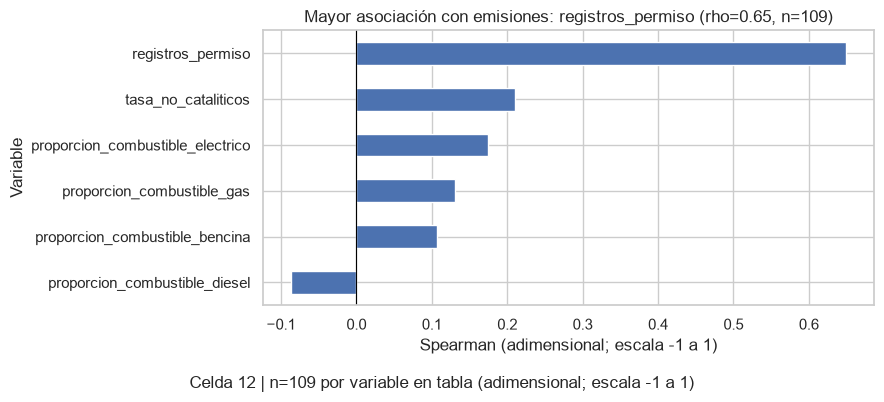

In [12]:
# Hallazgo 4 — relación de conteos de permisos con el objetivo (celda 12)
# Proporciones comparables: evitan introducir simultáneamente conteos redundantes de combustible.
for col in [c for c in df.columns if c.startswith("permisos_combustible_")]:
    df["proporcion_" + col.replace("permisos_combustible_", "combustible_")] = (
        pd.to_numeric(df[col], errors="coerce") /
        pd.to_numeric(df["registros_permiso"], errors="coerce").replace(0, np.nan)
    )
if {"permisos_no_cataliticos", "registros_catalitico"}.issubset(df.columns):
    df["tasa_no_cataliticos"] = (
        pd.to_numeric(df["permisos_no_cataliticos"], errors="coerce") /
        pd.to_numeric(df["registros_catalitico"], errors="coerce").replace(0, np.nan)
    )

conteos = [
    c for c in df.select_dtypes(include=np.number).columns
    if c == "registros_permiso" or c.startswith("proporcion_combustible_")
    or c == "tasa_no_cataliticos"
]

filas = []
for col in conteos:
    par = df[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
    rho = spearmanr(par[col], par[OBJETIVO]).statistic if len(par) >= 3 and par[col].nunique() > 1 else np.nan
    filas.append([col, rho, len(par), par[col].nunique()])

relaciones_num = pd.DataFrame(filas, columns=["variable", "spearman", "n", "valores_distintos"])
display(relaciones_num)

if not relaciones_num.dropna(subset=["spearman"]).empty:
    idx_top = relaciones_num.spearman.abs().idxmax()
    top_var = relaciones_num.loc[idx_top, "variable"]
    top_rho = relaciones_num.loc[idx_top, "spearman"]
    top_n = int(relaciones_num.loc[idx_top, "n"])

    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(relaciones_num))))
    relaciones_num.set_index("variable")["spearman"].sort_values().plot(kind="barh", ax=ax)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(
        title=f"Mayor asociación con emisiones: {top_var} (rho={top_rho:.2f}, n={top_n})",
        xlabel="Spearman (adimensional; escala -1 a 1)",
        ylabel="Variable"
    )
    fig.text(0.5, 0.01, f"Celda 12 | n={top_n} por variable en tabla (adimensional; escala -1 a 1)", ha="center")
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(CARPETA_FIGURAS / "04_spearman_permisos.png", dpi=160)
    plt.show()

    otros_max = relaciones_num.drop(idx_top)["spearman"].abs().max()
    h4_resultado = f"{top_var}: rho={top_rho:.3f}, n={top_n}; las demás variables de permisos tienen |rho| <= {otros_max:.3f}."
else:
    h4_resultado = f"{len(conteos)} conteos; Spearman no calculable"

n_nulos_perm = int(df["registros_permiso"].isna().sum())
h4_decision = (
    "Priorizar volumen (registros_permiso) y tasa_no_cataliticos disponibles al estimar; "
    f"imputar o filtrar {n_nulos_perm} fila(s) con nulo en permisos (n={int(df['registros_permiso'].notna().sum())} de {len(df)})."
)

hallazgo_4 = [
    "H4",
    h4_resultado,
    "figs/04_spearman_permisos.png",
    "12",
    "Composición y volumen de permisos",
    h4_decision
]

In [13]:
print(f"""
HALLAZGO 4
============================================================
• Resultado : {h4_resultado}
• Figura    : figs/04_spearman_permisos.png
• Pregunta  : Composición y volumen de permisos
• Decisión  : {h4_decision}
""")


HALLAZGO 4
• Resultado : registros_permiso: rho=0.650, n=109; las demás variables de permisos tienen |rho| <= 0.210.
• Figura    : figs/04_spearman_permisos.png
• Pregunta  : Composición y volumen de permisos
• Decisión  : Priorizar volumen (registros_permiso) y tasa_no_cataliticos disponibles al estimar; imputar o filtrar 1 fila(s) con nulo en permisos (n=109 de 110).



,comuna,variable,spearman,n
0,chiguayante,registros_permiso,0.636364,11
1,chiguayante,proporcion_combustible_bencina,-0.154545,11
2,chiguayante,proporcion_combustible_diesel,0.336364,11
3,chiguayante,proporcion_combustible_electrico,0.123920,11
4,chiguayante,proporcion_combustible_gas,-0.500000,11
5,chiguayante,tasa_no_cataliticos,0.605530,11
6,concepcion,registros_permiso,0.372727,11
7,concepcion,proporcion_combustible_bencina,-0.090909,11
8,concepcion,proporcion_combustible_diesel,0.100000,11
9,concepcion,proporcion_combustible_electrico,0.353584,11


,comunas_con_datos,mediana_rho,proporcion_mismo_signo
variable,,,
proporcion_combustible_bencina,10,0.054545,0.600000
proporcion_combustible_diesel,10,-0.045455,0.600000
proporcion_combustible_electrico,10,0.197108,0.700000
proporcion_combustible_gas,6,0.250000,0.833333
registros_permiso,10,0.659091,1.000000
tasa_no_cataliticos,10,0.284487,0.800000


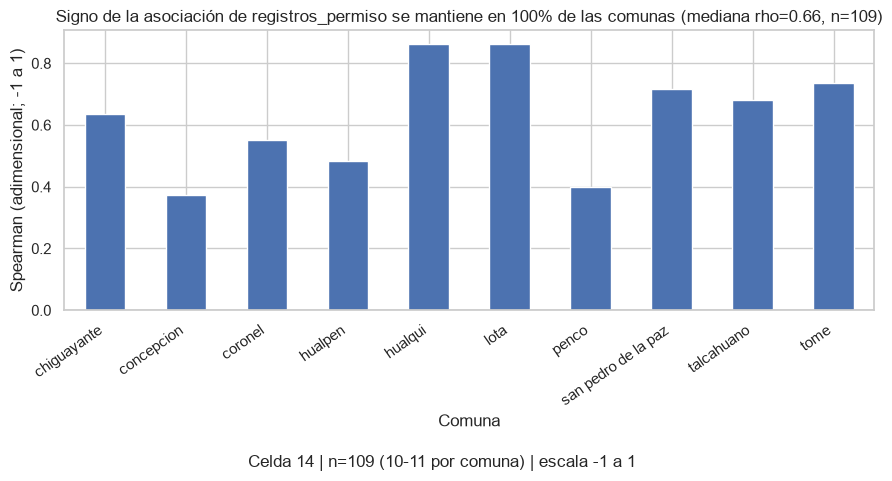

In [14]:
# Hallazgo 5 — segmentación por comuna (celda 14)
segmentos = []
for comuna, sub in df.groupby("comuna_norm"):
    for col in conteos:
        par = sub[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
        if len(par) >= 3 and par[col].nunique() > 1:
            rho = spearmanr(par[col], par[OBJETIVO]).statistic
            segmentos.append([comuna, col, rho, len(par)])

seg = pd.DataFrame(segmentos, columns=["comuna", "variable", "spearman", "n"])
display(seg)

if not seg.empty:
    resumen = seg.groupby("variable").agg(
        comunas_con_datos=("comuna", "nunique"),
        mediana_rho=("spearman", "median"),
        proporcion_mismo_signo=("spearman", lambda x: max((x > 0).mean(), (x < 0).mean()))
    )
    display(resumen)

    # Seleccionamos la variable principal del H4 ('registros_permiso') en vez de la primera alfabética
    col_plot = "registros_permiso" if "registros_permiso" in resumen.index else resumen["mediana_rho"].abs().idxmax()
    sub_plot = seg[seg.variable == col_plot]
    n_real_h5 = int(sub_plot["n"].sum())
    med_rho_plot = resumen.loc[col_plot, "mediana_rho"]
    prop_signo_plot = resumen.loc[col_plot, "proporcion_mismo_signo"] * 100

    fig, ax = plt.subplots(figsize=(9, 4.8))
    sub_plot.plot(x="comuna", y="spearman", kind="bar", legend=False, ax=ax)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(
        title=f"Signo de la asociación de {col_plot} se mantiene en {prop_signo_plot:.0f}% de las comunas (mediana rho={med_rho_plot:.2f}, n={n_real_h5})",
        xlabel="Comuna",
        ylabel="Spearman (adimensional; -1 a 1)"
    )
    plt.xticks(rotation=35, ha="right")
    fig.text(0.5, 0.01, f"Celda 14 | n={n_real_h5} ({int(sub_plot['n'].min())}-{int(sub_plot['n'].max())} por comuna) | escala -1 a 1", ha="center")
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(CARPETA_FIGURAS / "05_segmentacion.png", dpi=160)
    plt.show()

    prop_comb = resumen.loc[resumen.index.str.startswith("proporcion_combustible_"), "proporcion_mismo_signo"]
    rango_comb = f"{prop_comb.min()*100:.0f}% a {prop_comb.max()*100:.0f}%" if len(prop_comb) else "sin datos"
    h5_resultado = (
        f"{seg.comuna.nunique()} comunas; el signo de {col_plot} es el mismo en {prop_signo_plot:.0f}% "
        f"(mediana rho={med_rho_plot:.3f}, n={n_real_h5}); en las proporciones de combustible el signo común va de {rango_comb}."
    )
else:
    h5_resultado = "Sin correlaciones segmentadas calculables; n insuficiente"
    print("No hay suficientes pares para calcular relaciones dentro de comunas; se declara limitación.")

h5_decision = (
    "Mantener efectos globales solo para volumen (registros_permiso) y antigüedad (tasa_no_cataliticos); "
    "evitar asumir relación universal en tipos de combustible por cambio de signo entre comunas."
)

hallazgo_5 = [
    "H5",
    h5_resultado,
    "figs/05_segmentacion.png",
    "14",
    "Estabilidad territorial",
    h5_decision
]

In [15]:
print(f"""
HALLAZGO 5
============================================================
• Resultado : {h5_resultado}
• Figura    : figs/05_segmentacion.png
• Pregunta  : Estabilidad territorial
• Decisión  : {h5_decision}
""")


HALLAZGO 5
• Resultado : 10 comunas; el signo de registros_permiso es el mismo en 100% (mediana rho=0.659, n=109); en las proporciones de combustible el signo común va de 60% a 83%.
• Figura    : figs/05_segmentacion.png
• Pregunta  : Estabilidad territorial
• Decisión  : Mantener efectos globales solo para volumen (registros_permiso) y antigüedad (tasa_no_cataliticos); evitar asumir relación universal en tipos de combustible por cambio de signo entre comunas.



grupo_vehiculo,Buses,Camiones,Comerciales livianos,Livianos pasajeros,Motocicletas,Taxis
comuna_norm,,,,,,
chiguayante,18.751594,39.272555,41.561697,85.097187,15.493590,0.000000
concepcion,25.091821,49.868583,54.270919,135.875382,11.723629,63.504442
coronel,28.440566,48.528180,49.582631,124.233154,18.675909,76.364554
hualpen,17.344181,41.592185,41.285180,119.086865,22.415237,43.226584
hualqui,15.567966,20.049061,42.227148,74.484607,15.293213,0.000000
lota,28.427585,15.855048,61.510803,83.665863,17.344950,65.633514
penco,21.191035,44.580173,48.176028,113.832675,19.049737,57.628677
san pedro de la paz,21.604726,39.468638,60.235619,134.296419,11.841507,46.741908
talcahuano,17.175050,52.782166,60.962375,137.580324,15.867659,48.090057


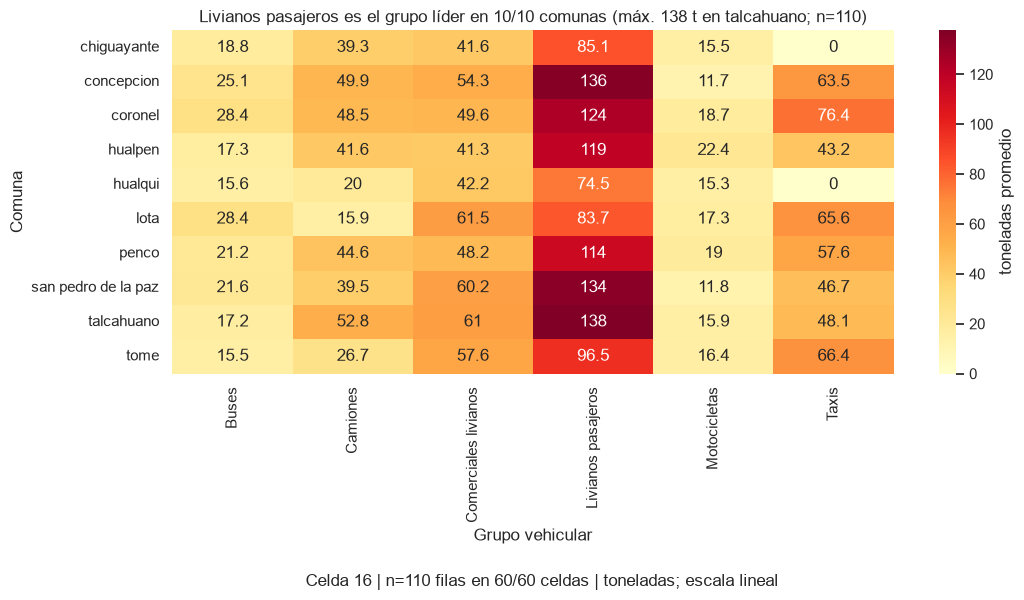

In [16]:
# Hallazgo 6 — comparación de grupos dentro de comuna (celda 16)
tabla = df.pivot_table(index="comuna_norm", columns="grupo_vehiculo", values=OBJETIVO, aggfunc="mean")
display(tabla)

n_filas_h6 = int(df[OBJETIVO].notna().sum())
n_combos = int(tabla.notna().sum().sum())
total_combos = tabla.shape[0] * tabla.shape[1]
max_val_h6 = tabla.max().max()
max_grupo_h6 = tabla.max().idxmax()
max_comuna_h6 = tabla[max_grupo_h6].idxmax()

lider_global = tabla.mean().idxmax()
n_lider = int((tabla.idxmax(axis=1) == lider_global).sum())
n_com_h6 = tabla.shape[0]
min_val_h6 = tabla.min().min()
min_grupo_h6 = tabla.min().idxmin()
min_comuna_h6 = tabla[min_grupo_h6].idxmin()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(tabla, annot=True, fmt=".3g", cmap="YlOrRd",
            cbar_kws={"label": "toneladas promedio"}, ax=ax)

ax.set(
    title=f"{lider_global} es el grupo líder en {n_lider}/{n_com_h6} comunas (máx. {max_val_h6:.3g} t en {max_comuna_h6}; n={n_filas_h6})",
    xlabel="Grupo vehicular",
    ylabel="Comuna"
)
fig.text(0.5, 0.01, f"Celda 16 | n={n_filas_h6} filas en {n_combos}/{total_combos} celdas | toneladas; escala lineal", ha="center")
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(CARPETA_FIGURAS / "06_comuna_grupo.png", dpi=160)
plt.show()

# Registro estructurado de los 5 requisitos
h6_resultado = (
    f"{n_combos}/{total_combos} combinaciones con datos (n={n_filas_h6}); {lider_global} lidera en {n_lider}/{n_com_h6} comunas; "
    f"máximo en {max_comuna_h6} - {max_grupo_h6} ({max_val_h6:.3g} t); mínimo en {min_comuna_h6} - {min_grupo_h6} ({min_val_h6:.3g} t)."
)
h6_decision = (
    "Considerar la interacción comuna x grupo_vehiculo (por eso un modelo de árboles); "
    "las celdas con 0 t se conservan tal como vienen del RUEA."
)

hallazgo_6 = [
    "H6",
    h6_resultado,
    "figs/06_comuna_grupo.png",
    "16",
    "Interacción territorio-tipo",
    h6_decision
]


In [17]:
print(f"""
HALLAZGO 6
============================================================
• Resultado : {h6_resultado}
• Figura    : figs/06_comuna_grupo.png
• Pregunta  : Interacción territorio-tipo
• Decisión  : {h6_decision}
""")


HALLAZGO 6
• Resultado : 60/60 combinaciones con datos (n=110); Livianos pasajeros lidera en 10/10 comunas; máximo en talcahuano - Livianos pasajeros (138 t); mínimo en chiguayante - Taxis (0 t).
• Figura    : figs/06_comuna_grupo.png
• Pregunta  : Interacción territorio-tipo
• Decisión  : Considerar la interacción comuna x grupo_vehiculo (por eso un modelo de árboles); las celdas con 0 t se conservan tal como vienen del RUEA.



### 3.3 Pregunta refinada e hipótesis falsables
La pregunta se acota a la estimación por grupo vehicular y comuna. El año queda como clave de integración y no como dimensión de pronóstico. Las hipótesis se contrastan con las filas de la bitácora.

In [18]:
hipotesis = pd.DataFrame([
 ["H1","A igualdad de comuna y grupo, mayores conteos de permisos asociados a un grupo se relacionarán con mayores emisiones estimadas.",
  "H4 y H5","Se contrasta con signo y magnitud de Spearman por comuna y luego con MAE en CV."],
 ["H2","Las emisiones promedio diferirán entre grupos vehiculares y esas diferencias persistirán en varias comunas.",
  "H2 y H6","Se contrasta con medias por grupo, heatmap y desempeño fuera de comuna."],
 ["H3","La relación entre conteos de permisos y emisiones no tendrá necesariamente el mismo signo en todas las comunas.",
  "H5","Si el signo cambia, se limita la generalización y se evita una interpretación global."]
],columns=["ID","Hipótesis falsable","Hallazgos asociados","Cómo se contrasta"])
display(hipotesis)

,ID,Hipótesis falsable,Hallazgos asociados,Cómo se contrasta
0,H1,"A igualdad de comuna y grupo, mayores conteos ...",H4 y H5,Se contrasta con signo y magnitud de Spearman ...
1,H2,Las emisiones promedio diferirán entre grupos ...,H2 y H6,"Se contrasta con medias por grupo, heatmap y d..."
2,H3,La relación entre conteos de permisos y emisio...,H5,"Si el signo cambia, se limita la generalizació..."


In [19]:
terminos_pregunta = pd.DataFrame([
 ["Emisiones por tipo de vehículo","emisiones_agregadas_toneladas","Objetivo; no predictor"],
 ["Tipo de vehículo","grupo_vehiculo","Predictor categórico"],
 ["Territorio","comuna_norm","Variable de agrupación (partición y validación por comuna); no es predictor"],
 ["Composición por combustible","permisos_combustible_*","Candidatas; conteos administrativos"],
 ["Tecnología catalítica","permisos_cataliticos / permisos_no_cataliticos","Candidatas; conteos administrativos"],
 ["Año","año","Clave/segmentación; fuera del modelo porque no se pronostica tiempo"],
 ["Registros RUEA","registros_ruea","Fuera: derivada del mismo proceso de construcción del objetivo"],
],columns=["Término de la pregunta","Columna del dataset","Uso"])
display(terminos_pregunta)

,Término de la pregunta,Columna del dataset,Uso
0,Emisiones por tipo de vehículo,emisiones_agregadas_toneladas,Objetivo; no predictor
1,Tipo de vehículo,grupo_vehiculo,Predictor categórico
2,Territorio,comuna_norm,Variable de agrupación (partición y validación...
3,Composición por combustible,permisos_combustible_*,Candidatas; conteos administrativos
4,Tecnología catalítica,permisos_cataliticos / permisos_no_cataliticos,Candidatas; conteos administrativos
5,Año,año,Clave/segmentación; fuera del modelo porque no...
6,Registros RUEA,registros_ruea,Fuera: derivada del mismo proceso de construcc...


### 3.4 Ficha de características relevantes
Se calcula Spearman para numérica–numérica y promedio por categoría con `n` para categórica–numérica. La ficha incluye variables que entran y que quedan fuera, disponibilidad, redundancia y riesgo de fuga.

In [20]:
# 1. Crear variables derivadas de composición
for col in [c for c in df.columns if c.startswith("permisos_combustible_")]:
    df["proporcion_" + col.replace("permisos_combustible_", "combustible_")] = (
        pd.to_numeric(df[col], errors="coerce") /
        pd.to_numeric(df["registros_permiso"], errors="coerce").replace(0, np.nan)
    )
if {"permisos_no_cataliticos", "registros_catalitico"}.issubset(df.columns):
    df["tasa_no_cataliticos"] = (
        pd.to_numeric(df["permisos_no_cataliticos"], errors="coerce") /
        pd.to_numeric(df["registros_catalitico"], errors="coerce").replace(0, np.nan)
    )

# 2. Incluir TODAS las variables relevantes (las que entran Y las que quedan fuera)
todas_candidatas = [
    "comuna_norm", "grupo_vehiculo", "registros_permiso",
    "proporcion_combustible_bencina", "proporcion_combustible_diesel",
    "proporcion_combustible_electrico", "proporcion_combustible_gas",
    "tasa_no_cataliticos",
    # Variables que quedan fuera o transformadas (obligatorias según pauta):
    "registros_ruea", "año", "permisos_no_cataliticos", "registros_catalitico"
] + [c for c in df.columns if c.startswith("permisos_combustible_")]

todas_candidatas = list(dict.fromkeys(c for c in todas_candidatas if c in df.columns))

# grupo_vehiculo: ¿el grupo líder es el mismo dentro de cada comuna?
top_global = df.groupby("grupo_vehiculo")[OBJETIVO].mean().idxmax()
top_por_comuna = (df.groupby(["comuna_norm", "grupo_vehiculo"])[OBJETIVO].mean()
                    .groupby("comuna_norm").idxmax().map(lambda t: t[1]))
frac_grupo = float((top_por_comuna == top_global).mean())
n_com = int(top_por_comuna.shape[0])
sobrevive_grupo = f"Sí: {top_global} lidera en {int(frac_grupo*n_com)}/{n_com} comunas" if frac_grupo >= 0.8 \
                  else f"Parcial: {top_global} lidera en {int(frac_grupo*n_com)}/{n_com} comunas"

# comuna_norm: ¿el orden de las comunas se repite entre años?
m_anio = df.pivot_table(index="comuna_norm", columns="año", values=OBJETIVO, aggfunc="mean")
anios = sorted(m_anio.columns)
rho_anios = spearmanr(m_anio[anios[0]], m_anio[anios[1]]).statistic
sobrevive_comuna = f"Orden de comunas entre {anios[0]} y {anios[1]}: rho={rho_anios:.2f} (n={len(m_anio)} comunas)"

def sobrev_num(v):
    """Estabilidad del signo de la asociación entre comunas (calculada en el hallazgo H5)."""
    if v not in resumen.index:
        return "No evaluada en la segmentación"
    r = resumen.loc[v]
    p = float(r["proporcion_mismo_signo"]); n_c = int(r["comunas_con_datos"])
    etiqueta = "Sí" if p >= 0.8 else ("Parcial" if p >= 0.6 else "No")
    return f"{etiqueta} (signo común en {round(p * n_c)}/{n_c} comunas, mediana rho={r['mediana_rho']:.3f}; H5)"

filas = []
for col in todas_candidatas:
    s = df[col]
    falt = 100 * s.isna().mean()
    es_num = pd.api.types.is_numeric_dtype(s)
    tipo = "numérica" if es_num else "categórica"

    # Cálculo de relación con el objetivo (medida, valor y n)
    if es_num:
        par = df[[col, OBJETIVO]].apply(pd.to_numeric, errors="coerce").dropna()
        rho = spearmanr(par[col], par[OBJETIVO]).statistic if len(par) >= 3 and par[col].nunique() > 1 else np.nan
        n_par = len(par)
        relacion = f"Spearman: rho={rho:.3f} (n={n_par})" if pd.notna(rho) else f"Spearman: no calculable (n={n_par})"
    else:
        tmp = df[[col, OBJETIVO]].dropna()
        res = tmp.groupby(col, observed=True)[OBJETIVO].agg(["mean", "count"])
        n_par = int(res["count"].sum())
        relacion = (
            f"Media por cat.: min={res['mean'].min():.3g} t ({res['mean'].idxmin()}), "
            f"max={res['mean'].max():.3g} t ({res['mean'].idxmax()}) (n={n_par})"
        )

    # Reglas de decisión, fuga, redundancia y supervivencia con cifras
    if col == "comuna_norm":
        sobrevive =  sobrevive_comuna
        redundante = "No evidente"
        fuga = "No (atributo geográfico)"
        disp_falt = f"{falt:.1f}% faltante; disponible ex ante"
        decision = "agrupación (no predictor)"
        motivo = "Define las particiones por comuna; como la validación usa comunas no vistas, el one-hot no puede aportar."

    elif col == "grupo_vehiculo":
        sobrevive =  sobrevive_grupo
        redundante = "No evidente"
        fuga = "No (categoría fija)"
        disp_falt = f"{falt:.1f}% faltante; disponible ex ante"
        decision = "entra"
        motivo = f"Brecha entre grupos: {res['mean'].max():.3g} t ({res['mean'].idxmax()}) vs {res['mean'].min():.3g} t ({res['mean'].idxmin()}), n={n_par}."

    elif col == "registros_permiso":
        sobrevive = sobrev_num(col)
        redundante = "Suma de permisos_combustible_*"
        fuga = "Moderado (verificar cierre anual ex ante)"
        disp_falt = f"{falt:.2f}% faltante ({int(s.isna().sum())} nulo(s)); condicionada a corte anual"
        decision = "entra transformada"
        motivo = f"Asociación numérica con el objetivo (rho={rho:.3f}, n={n_par}); requiere log/escalado."

    elif col.startswith("proporcion_combustible_"):
        sobrevive = sobrev_num(col)
        redundante = "Cierra a 1 entre las 4 proporciones"
        fuga = "Moderado (mismo año de registro)"
        disp_falt = f"{falt:.2f}% faltante; derivada de permisos"
        decision = "entra transformada"
        motivo = f"Normaliza composición frente a conteos crudos (rho={rho:.3f}, n={n_par})."

    elif col == "tasa_no_cataliticos":
        sobrevive = sobrev_num(col)
        redundante = "permisos_no_cataliticos / registros_catalitico"
        fuga = "Moderado (mismo año de registro)"
        disp_falt = f"{falt:.2f}% faltante; derivada de permisos"
        decision = "entra transformada"
        motivo = f"Proxy de antigüedad del parque (rho={rho:.3f}, n={n_par})."

    elif col == "registros_ruea":
        sobrevive = "No evaluada (excluida por fuga)"
        redundante = "Directamente con emisiones_agregadas"
        fuga = "ALTO (espejo del cálculo del objetivo)"
        disp_falt = f"{falt:.2f}% faltante; no disponible ex ante"
        decision = "fuera"
        motivo = f"Fuga de datos: se construye en el mismo proceso del objetivo (rho={rho:.3f}, n={n_par})."

    elif col == "año":
        sobrevive = "Clave de cruce temporal"
        redundante = "No evidente"
        fuga = "No (dimensión temporal fija)"
        disp_falt = f"{falt:.1f}% faltante; clave de integración"
        decision = "fuera"
        motivo = f"Alcance del estudio no pronostica tiempo (n={n_par}, valores={df[col].nunique()})."

    else:  # Conteos crudos (permisos_combustible_*, permisos_no_cataliticos, registros_catalitico)
        sobrevive = "Reemplazada por proporción/tasa"
        redundante = "Colineal con registros_permiso"
        fuga = "Moderado (mismo año)"
        disp_falt = f"{falt:.2f}% faltante; reemplazada"
        decision = "fuera"
        motivo = f"Conteo crudo redundante (rho={rho:.3f}, n={n_par}); ya incluido como proporción/tasa."

    filas.append([
        col, tipo, relacion, sobrevive, redundante, fuga,
        disp_falt, decision, motivo, "Sección 4 (Ficha candidatas)"
    ])

pd.set_option("display.max_colwidth", None)
ficha_variables = pd.DataFrame(filas, columns=[
    "variable", "tipo", "relación con el objetivo (medida, valor y n)",
    "¿sobrevive a la segmentación?", "redundante con", "riesgo de fuga",
    "% faltante y disponibilidad", "decisión", "por qué (una línea, con cifra)", "celda"
])
display(ficha_variables)
ficha_variables.to_csv(SALIDAS / "ficha_variables_candidatas.csv", index=False, encoding="utf-8-sig")

,variable,tipo,"relación con el objetivo (medida, valor y n)",¿sobrevive a la segmentación?,redundante con,riesgo de fuga,% faltante y disponibilidad,decisión,"por qué (una línea, con cifra)",celda
0,comuna_norm,categórica,"Media por cat.: min=30.5 t (hualqui), max=56.1 t (concepcion) (n=110)",Orden de comunas entre 2022 y 2023: rho=0.71 (n=10 comunas),No evidente,No (atributo geográfico),0.0% faltante; disponible ex ante,agrupación (no predictor),"Define las particiones por comuna; como la validación usa comunas no vistas, el one-hot no puede aportar.",Sección 4 (Ficha candidatas)
1,grupo_vehiculo,categórica,"Media por cat.: min=16.4 t (Motocicletas), max=110 t (Livianos pasajeros) (n=110)",Sí: Livianos pasajeros lidera en 10/10 comunas,No evidente,No (categoría fija),0.0% faltante; disponible ex ante,entra,"Brecha entre grupos: 110 t (Livianos pasajeros) vs 16.4 t (Motocicletas), n=110.",Sección 4 (Ficha candidatas)
2,registros_permiso,numérica,Spearman: rho=0.650 (n=109),"Sí (signo común en 10/10 comunas, mediana rho=0.659; H5)",Suma de permisos_combustible_*,Moderado (verificar cierre anual ex ante),0.91% faltante (1 nulo(s)); condicionada a corte anual,entra transformada,"Asociación numérica con el objetivo (rho=0.650, n=109); requiere log/escalado.",Sección 4 (Ficha candidatas)
3,proporcion_combustible_bencina,numérica,Spearman: rho=0.106 (n=109),"Parcial (signo común en 6/10 comunas, mediana rho=0.055; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=0.106, n=109).",Sección 4 (Ficha candidatas)
4,proporcion_combustible_diesel,numérica,Spearman: rho=-0.087 (n=109),"Parcial (signo común en 6/10 comunas, mediana rho=-0.045; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=-0.087, n=109).",Sección 4 (Ficha candidatas)
5,proporcion_combustible_electrico,numérica,Spearman: rho=0.174 (n=109),"Parcial (signo común en 7/10 comunas, mediana rho=0.197; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=0.174, n=109).",Sección 4 (Ficha candidatas)
6,proporcion_combustible_gas,numérica,Spearman: rho=0.131 (n=109),"Sí (signo común en 5/6 comunas, mediana rho=0.250; H5)",Cierra a 1 entre las 4 proporciones,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Normaliza composición frente a conteos crudos (rho=0.131, n=109).",Sección 4 (Ficha candidatas)
7,tasa_no_cataliticos,numérica,Spearman: rho=0.210 (n=109),"Sí (signo común en 8/10 comunas, mediana rho=0.284; H5)",permisos_no_cataliticos / registros_catalitico,Moderado (mismo año de registro),0.91% faltante; derivada de permisos,entra transformada,"Proxy de antigüedad del parque (rho=0.210, n=109).",Sección 4 (Ficha candidatas)
8,registros_ruea,numérica,Spearman: rho=0.744 (n=110),No evaluada (excluida por fuga),Directamente con emisiones_agregadas,ALTO (espejo del cálculo del objetivo),0.00% faltante; no disponible ex ante,fuera,"Fuga de datos: se construye en el mismo proceso del objetivo (rho=0.744, n=110).",Sección 4 (Ficha candidatas)
9,año,numérica,Spearman: rho=0.110 (n=110),Clave de cruce temporal,No evidente,No (dimensión temporal fija),0.0% faltante; clave de integración,fuera,"Alcance del estudio no pronostica tiempo (n=110, valores=2).",Sección 4 (Ficha candidatas)


**Decisión de entrada:** `grupo_vehiculo` entra. `comuna_norm` no es predictor: se usa solo como variable de agrupación para particionar y validar por comuna (con comunas no vistas en prueba, su one-hot no puede aportar). Los conteos de permisos entran transformados con `log1p`, pero su uso queda condicionado a confirmar que la información esté disponible antes de producir la estimación; si no se cumple, deben cambiarse a `pendiente` y excluirse de Parte 4. `año`, `registros_ruea`, el objetivo y cualquier derivada del objetivo quedan fuera.

# Parte 4
## Modelado y evaluación
Problema de regresión supervisada. La predicción no es temporal. La prueba se reserva separando comunas completas; la validación cruzada también agrupa por comuna para medir generalización territorial.

### 4.1 Diseño de evaluación
**Tipo de problema**: Regresión supervisada para estimar emisiones agregadas (toneladas) por comuna y grupo vehicular.

**Error más costoso**: Subestimar emisiones, ya que una comuna o grupo vehicular recibiría menos atención o recursos ambientales de los necesarios.

**Métrica principal y secundarias**: Se elige MAE en toneladas como métrica principal porque mide el desvío promedio en la misma unidad de la decisión y es directa de interpretar. Se reportan RMSE (penaliza más los errores grandes) y $R^2$ como secundarias. Como el MAE trata igual la sub y la sobreestimación, y lo más costoso es subestimar, se agregan tres medidas del error costoso: sesgo medio, subestimación media (t) y porcentaje de filas subestimadas (`perfil_error`, celda de la evaluación final).

**Baseline y partición**: `DummyRegressor(strategy="median")` como línea base trivial. Partición territorial (GroupShuffleSplit 80/20 + GroupKFold de 4 pliegues sobre `comuna_norm`) para evaluar generalización a comunas no vistas; el conjunto de prueba se usa una sola vez, también para el baseline.


In [21]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Selección de predictores aprobados desde la ficha
variables_modelo = ficha_variables.loc[
    ficha_variables["decisión"].isin(["entra", "entra transformada"]), "variable"
].tolist()
prohibidas = {OBJETIVO, "año", "registros_ruea", "tiene_registro_permiso", "comuna_norm"}
variables_modelo = [c for c in variables_modelo if c not in prohibidas]
if not variables_modelo:
    raise ValueError("La ficha no dejó predictores aprobados.")

# 2. Preprocesamiento encapsulado en Pipeline (sin fuga de datos)
cols_cat = [c for c in variables_modelo if not pd.api.types.is_numeric_dtype(df[c])]
cols_num = [c for c in variables_modelo if c not in cols_cat]
cols_conteo = [c for c in cols_num if c.startswith("registros_") or c.startswith("permisos_")]
cols_otros = [c for c in cols_num if c not in cols_conteo]

transformaciones = []
if cols_conteo:
    transformaciones.append(("conteos", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler())
    ]), cols_conteo))
if cols_otros:
    transformaciones.append(("numericas", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_otros))
if cols_cat:
    transformaciones.append(("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat))

preprocesador = ColumnTransformer(transformaciones)

# 3. Partición territorial (Train/Test separado al inicio)
columnas_requeridas = list(dict.fromkeys(variables_modelo + ["comuna_norm", OBJETIVO]))
datos = df[columnas_requeridas].dropna(subset=[OBJETIVO, "comuna_norm"]).copy()
X = datos[variables_modelo]
y = datos[OBJETIVO]
grupos = datos["comuna_norm"]

if grupos.nunique() < 6 or len(datos) < 20:
    raise ValueError(f"Muestra insuficiente para test territorial + CV: n={len(datos)}, comunas={grupos.nunique()}. No reportar métricas inestables.")

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
idx_train, idx_test = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
groups_train = grupos.iloc[idx_train]

n_splits = min(4, groups_train.nunique())
cv = GroupKFold(n_splits=n_splits)
particiones = list(cv.split(X_train, y_train, groups=groups_train))

# 4. Baseline trivial (DummyRegressor con mediana) evaluado solo en train vía GroupKFold
dummy = Pipeline([
    ("prep", preprocesador),
    ("modelo", DummyRegressor(strategy="median"))
])

maes_dummy, rmses_dummy, r2s_dummy = [], [], []
for tr_idx, va_idx in particiones:
    dummy.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pred_va = dummy.predict(X_train.iloc[va_idx])
    maes_dummy.append(mean_absolute_error(y_train.iloc[va_idx], pred_va))
    rmses_dummy.append(np.sqrt(mean_squared_error(y_train.iloc[va_idx], pred_va)))
    r2s_dummy.append(r2_score(y_train.iloc[va_idx], pred_va))

dummy.fit(X_train, y_train)
valor_constante_dummy = dummy.named_steps["modelo"].constant_[0][0]

print(f"Predictores ({len(variables_modelo)}): {variables_modelo}")
print(f"Train: {X_train.shape} | Test reservado: {X_test.shape} | "
      f"Comunas train: {groups_train.nunique()} | Comunas test: {grupos.iloc[idx_test].nunique()}")
print(f"CV: {n_splits} particiones GroupKFold (conjunto de prueba reservado sin consultar).")
print("-" * 75)
print(f"Baseline DummyRegressor(median):")
print(f"  • Predicción constante en train : {valor_constante_dummy:.4g} t")
print(f"  • MAE CV (métrica principal)    : {np.mean(maes_dummy):.4g} t (± {np.std(maes_dummy):.4g} t)")
print(f"  • RMSE CV (secundaria)          : {np.mean(rmses_dummy):.4g} t")
print(f"  • R² CV (secundaria)            : {np.mean(r2s_dummy):.3f}")

Predictores (7): ['grupo_vehiculo', 'registros_permiso', 'proporcion_combustible_bencina', 'proporcion_combustible_diesel', 'proporcion_combustible_electrico', 'proporcion_combustible_gas', 'tasa_no_cataliticos']
Train: (88, 7) | Test reservado: (22, 7) | Comunas train: 8 | Comunas test: 2
CV: 4 particiones GroupKFold (conjunto de prueba reservado sin consultar).
---------------------------------------------------------------------------
Baseline DummyRegressor(median):
  • Predicción constante en train : 39.5 t
  • MAE CV (métrica principal)    : 26.18 t (± 1.226 t)
  • RMSE CV (secundaria)          : 34.48 t
  • R² CV (secundaria)            : -0.086


### 4.2 Modelos y validación cruzada
Se comparan dos familias de modelos distintas entrenadas sobre los mismos 7 predictores aprobados en la ficha (sin discrepancias respecto a la sección 4):

* **Familia lineal regularizada (`Ridge`):** Permite estimar efectos aditivos por grupo vehicular y por composición de permisos, controlando mediante penalización $L_2$ la colinealidad estructural entre las proporciones de combustible (que suman 1).
* **Familia de ensambles basados en árboles (`RandomForestRegressor`):** Captura relaciones no lineales e interacciones de orden superior (como las diferencias entre grupos que cambian de una comuna a otra, vistas en H6) sin asumir linealidad ni requerir escalado de magnitudes, utilizando `criterion="absolute_error"` para optimizar medianas por hoja acorde a la métrica principal (MAE) y la asimetría moderada del objetivo (H1).

Para evitar optimismo por selección de hiperparámetros, la búsqueda de hiperparámetros (alpha en Ridge; grilla en Random Forest) se realiza dentro de cada partición externa (validación cruzada anidada con `GroupKFold` interno). Todos los modelos usan las mismas particiones externas y todo paso que aprende de los datos (`SimpleImputer`, `log1p`, `StandardScaler`) se ajusta exclusivamente sobre el entrenamiento de cada pliegue.

In [22]:
modelos_base = {
    "Baseline mediana": Pipeline([
        ("preparar", preprocesador),
        ("modelo", DummyRegressor(strategy="median"))
    ]),
    "Ridge": Pipeline([
        ("preparar", preprocesador),
        ("modelo", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("preparar", preprocesador),
        ("modelo", RandomForestRegressor(
            n_estimators=200, max_depth=None, min_samples_leaf=2,
            criterion="absolute_error", random_state=42, n_jobs=-1
        ))
    ])
}

parametros = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [2, 4, None],
    "modelo__min_samples_leaf": [2, 4]
}
n_combinaciones = int(np.prod([len(v) for v in parametros.values()]))
print("Grid RF:", parametros, "| combinaciones:", n_combinaciones,
      "| selección: MAE | semilla: 42")

resultados = []
for nombre, modelo in modelos_base.items():
    scores = []
    for train_idx, val_idx in particiones:
        modelo_fold = __import__("sklearn").base.clone(modelo)
        modelo_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
        pred = modelo_fold.predict(X_train.iloc[val_idx])
        yt = y_train.iloc[val_idx]
        scores.append((
            mean_absolute_error(yt, pred),
            mean_squared_error(yt, pred) ** 0.5,
            r2_score(yt, pred) if len(yt) > 1 else np.nan
        ))
    arr = np.asarray(scores, float)
    resultados.append([
        nombre,
        arr[:, 0].mean(), arr[:, 0].std(ddof=1),
        arr[:, 1].mean(), arr[:, 1].std(ddof=1),
        np.nanmean(arr[:, 2]), np.nanstd(arr[:, 2], ddof=1)
    ])

tabla_cv = pd.DataFrame(resultados, columns=[
    "modelo", "MAE media", "MAE desv", "RMSE media", "RMSE desv", "R2 media", "R2 desv"
])
display(tabla_cv)

Grid RF: {'modelo__n_estimators': [100, 300], 'modelo__max_depth': [2, 4, None], 'modelo__min_samples_leaf': [2, 4]} | combinaciones: 12 | selección: MAE | semilla: 42


,modelo,MAE media,MAE desv,RMSE media,RMSE desv,R2 media,R2 desv
0,Baseline mediana,26.176957,1.415532,34.482836,6.526472,-0.086419,0.114039
1,Ridge,13.268549,2.077201,16.396337,2.216944,0.734175,0.126222
2,Random Forest,13.856330,1.805380,17.589875,2.750451,0.690259,0.140616


In [23]:
# Búsqueda anidada de RF: cada partición externa reserva validación; GridSearch usa solo su subentrenamiento.
from sklearn.base import clone

rf_outer = []
for fold, (tr, va) in enumerate(particiones, start=1):
    Xtr, ytr = X_train.iloc[tr], y_train.iloc[tr]
    Xva, yva = X_train.iloc[va], y_train.iloc[va]
    grupos_tr = groups_train.iloc[tr]
    inner_splits = min(3, grupos_tr.nunique())
    if inner_splits < 2:
        raise ValueError("No hay grupos suficientes para búsqueda interna en este fold.")

    cv_inner = GroupKFold(n_splits=inner_splits)
    grid = GridSearchCV(
        clone(modelos_base["Random Forest"]),
        parametros,
        scoring="neg_mean_absolute_error",
        cv=cv_inner,
        n_jobs=-1,
        refit=True
    )
    grid.fit(Xtr, ytr, groups=grupos_tr)
    pred = grid.predict(Xva)

    rf_outer.append({
        "fold": fold,
        "MAE": mean_absolute_error(yva, pred),
        "RMSE": mean_squared_error(yva, pred) ** 0.5,
        "R2": r2_score(yva, pred) if len(yva) > 1 else np.nan,
        "mejores_parametros": grid.best_params_
    })

pd.set_option("display.max_colwidth", None)
rf_outer_df = pd.DataFrame(rf_outer)
display(rf_outer_df)

# Evitar duplicados si se re-ejecuta la celda
tabla_cv = tabla_cv[tabla_cv["modelo"] != "Random Forest (búsqueda anidada)"].reset_index(drop=True)
tabla_cv.loc[len(tabla_cv)] = [
    "Random Forest (búsqueda anidada)",
    rf_outer_df.MAE.mean(), rf_outer_df.MAE.std(ddof=1),
    rf_outer_df.RMSE.mean(), rf_outer_df.RMSE.std(ddof=1),
    rf_outer_df.R2.mean(), rf_outer_df.R2.std(ddof=1)
]
display(tabla_cv.sort_values("MAE media"))

,fold,MAE,RMSE,R2,mejores_parametros
0,1,14.375903,18.198909,0.619513,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 300}"
1,2,15.256559,19.354689,0.759981,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}"
2,3,11.563475,14.462509,0.829348,"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 100}"
3,4,14.146538,19.516391,0.514782,"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 300}"


,modelo,MAE media,MAE desv,RMSE media,RMSE desv,R2 media,R2 desv
1,Ridge,13.268549,2.077201,16.396337,2.216944,0.734175,0.126222
3,Random Forest (búsqueda anidada),13.835618,1.588530,17.883124,2.354669,0.680906,0.141013
2,Random Forest,13.856330,1.805380,17.589875,2.750451,0.690259,0.140616
0,Baseline mediana,26.176957,1.415532,34.482836,6.526472,-0.086419,0.114039


In [24]:
parametros_ridge = {"modelo__alpha": [0.01, 0.1, 1, 10, 100, 1000]}

ridge_outer = []
for fold, (tr, va) in enumerate(particiones, start=1):
    Xtr, ytr = X_train.iloc[tr], y_train.iloc[tr]
    Xva, yva = X_train.iloc[va], y_train.iloc[va]
    grupos_tr = groups_train.iloc[tr]
    cv_inner = GroupKFold(n_splits=min(3, grupos_tr.nunique()))
    g = GridSearchCV(clone(modelos_base["Ridge"]), parametros_ridge,
                     scoring="neg_mean_absolute_error", cv=cv_inner, n_jobs=-1, refit=True)
    g.fit(Xtr, ytr, groups=grupos_tr)
    pred = g.predict(Xva)
    ridge_outer.append({
        "fold": fold,
        "MAE": mean_absolute_error(yva, pred),
        "RMSE": mean_squared_error(yva, pred) ** 0.5,
        "R2": r2_score(yva, pred) if len(yva) > 1 else np.nan,
        "mejores_parametros": g.best_params_,
    })
ridge_outer_df = pd.DataFrame(ridge_outer)
display(ridge_outer_df)

tabla_cv = tabla_cv[tabla_cv["modelo"] != "Ridge (búsqueda anidada)"].reset_index(drop=True)
tabla_cv.loc[len(tabla_cv)] = [
    "Ridge (búsqueda anidada)",
    ridge_outer_df.MAE.mean(), ridge_outer_df.MAE.std(ddof=1),
    ridge_outer_df.RMSE.mean(), ridge_outer_df.RMSE.std(ddof=1),
    ridge_outer_df.R2.mean(), ridge_outer_df.R2.std(ddof=1),
]
display(tabla_cv.sort_values("MAE media"))

,fold,MAE,RMSE,R2,mejores_parametros
0,1,11.397088,15.897880,0.709646,{'modelo__alpha': 0.01}
1,2,14.460514,17.448433,0.804932,{'modelo__alpha': 1}
2,3,13.305770,15.398647,0.806541,{'modelo__alpha': 1}
3,4,14.974159,18.883169,0.545757,{'modelo__alpha': 1}


,modelo,MAE media,MAE desv,RMSE media,RMSE desv,R2 media,R2 desv
1,Ridge,13.268549,2.077201,16.396337,2.216944,0.734175,0.126222
4,Ridge (búsqueda anidada),13.534382,1.586502,16.907032,1.580279,0.716719,0.122648
3,Random Forest (búsqueda anidada),13.835618,1.588530,17.883124,2.354669,0.680906,0.141013
2,Random Forest,13.856330,1.805380,17.589875,2.750451,0.690259,0.140616
0,Baseline mediana,26.176957,1.415532,34.482836,6.526472,-0.086419,0.114039


### 4.3 Ajuste final, comparación y elección
La búsqueda final se ajusta solo con el conjunto de entrenamiento. **Primero** se compara cada modelo con el baseline: solo cuenta como mejora si el MAE de CV baja más que la desviación entre pliegues del baseline. **Después**, entre los que sí superan al baseline, si la diferencia entre ellos es menor que la desviación entre pliegues se declara empate práctico y se prefiere Ridge por simplicidad. Si ninguno supera al baseline, se dice explícitamente. El test se evalúa una sola vez.


In [25]:
busqueda_ridge = GridSearchCV(
    modelos_base["Ridge"], parametros_ridge, scoring="neg_mean_absolute_error",
    cv=GroupKFold(n_splits=min(4, groups_train.nunique())), n_jobs=-1, refit=True)
busqueda_ridge.fit(X_train, y_train, groups=groups_train)
print("Mejor alpha Ridge:", busqueda_ridge.best_params_)

# Sensibilidad de alpha: MAE de validación (búsqueda final, solo entrenamiento) para cada valor de la grilla
sens_alpha = pd.DataFrame({
    "alpha": [p["modelo__alpha"] for p in busqueda_ridge.cv_results_["params"]],
    "MAE CV (t)": -busqueda_ridge.cv_results_["mean_test_score"],
    "desv. entre pliegues (t, ddof=0)": busqueda_ridge.cv_results_["std_test_score"],
}).sort_values("alpha").reset_index(drop=True)
display(sens_alpha)
alphas_por_pliegue = [p["modelo__alpha"] for p in ridge_outer_df["mejores_parametros"]]
print("Alpha elegido en cada pliegue externo (búsqueda anidada):", alphas_por_pliegue)
print(f"MAE CV según alpha: de {sens_alpha['MAE CV (t)'].min():.3g} t a {sens_alpha['MAE CV (t)'].max():.3g} t")
_mejor = sens_alpha["MAE CV (t)"].idxmin()
_umbral = sens_alpha.loc[_mejor, "MAE CV (t)"] + sens_alpha.loc[_mejor, "desv. entre pliegues (t, ddof=0)"]
alphas_equivalentes = sens_alpha.loc[sens_alpha["MAE CV (t)"] <= _umbral, "alpha"].tolist()
print(f"Alphas con MAE dentro de 1 desviación del mejor: {alphas_equivalentes}")


Mejor alpha Ridge: {'modelo__alpha': 0.1}


,alpha,MAE CV (t),"desv. entre pliegues (t, ddof=0)"
0,0.01,13.246576,1.542063
1,0.10,13.227161,1.554046
2,1.00,13.268549,1.798909
3,10.00,14.718473,2.821861
4,100.00,19.948211,2.035645
5,1000.00,25.319389,0.737146


Alpha elegido en cada pliegue externo (búsqueda anidada): [0.01, 1, 1, 1]
MAE CV según alpha: de 13.2 t a 25.3 t
Alphas con MAE dentro de 1 desviación del mejor: [0.01, 0.1, 1.0, 10.0]


In [26]:
# Búsqueda final del RF usando únicamente entrenamiento
cv_final=GroupKFold(n_splits=min(4,groups_train.nunique()))
busqueda_rf=GridSearchCV(modelos_base["Random Forest"],parametros,
    scoring="neg_mean_absolute_error",cv=cv_final,n_jobs=-1,refit=True)
busqueda_rf.fit(X_train,y_train,groups=groups_train)
print("Mejores hiperparámetros RF:",busqueda_rf.best_params_)
print("Combinaciones:",n_combinaciones,"| mejor MAE CV:",-busqueda_rf.best_score_)

# Comparar Ridge con RF usando resultados externos comparables.
ridge_mae=float(tabla_cv.loc[tabla_cv.modelo=="Ridge","MAE media"].iloc[0])
ridge_sd=float(tabla_cv.loc[tabla_cv.modelo=="Ridge","MAE desv"].iloc[0])
rf_mae=float(rf_outer_df.MAE.mean())
rf_sd=float(rf_outer_df.MAE.std(ddof=1))
base_mae = float(tabla_cv.loc[tabla_cv.modelo == "Baseline mediana", "MAE media"].iloc[0])
base_sd  = float(tabla_cv.loc[tabla_cv.modelo == "Baseline mediana", "MAE desv"].iloc[0])

candidatos = {
    "Ridge (alpha optimizado)":  ("Ridge (búsqueda anidada)",          busqueda_ridge.best_estimator_),
    "Random Forest optimizado":  ("Random Forest (búsqueda anidada)",  busqueda_rf.best_estimator_),
}
res = {}
for nombre, (fila, est) in candidatos.items():
    m = float(tabla_cv.loc[tabla_cv.modelo == fila, "MAE media"].iloc[0])
    s = float(tabla_cv.loc[tabla_cv.modelo == fila, "MAE desv"].iloc[0])
    res[nombre] = {"mae": m, "sd": s, "est": est, "supera": (base_mae - m) > base_sd}

validos = {n: r for n, r in res.items() if r["supera"]}      # Paso 1: ¿supera al baseline?
if not validos:
    mejor = min(res, key=lambda n: res[n]["mae"])
    elegido_nombre, modelo_elegido = mejor, res[mejor]["est"]
    veredicto = (f"Ningún modelo supera al baseline (MAE {base_mae:.3g} ± {base_sd:.3g}) por más de su "
                 f"desviación entre pliegues; se reporta {mejor} por menor MAE, sin utilidad demostrada para decidir.")
elif len(validos) == 1:
    elegido_nombre = next(iter(validos)); modelo_elegido = validos[elegido_nombre]["est"]
    veredicto = "Único modelo que supera al baseline por más de su desviación."
else:                                                         # Paso 2: empate solo entre los que sí superan
    a, b = sorted(validos, key=lambda n: validos[n]["mae"])
    if abs(validos[a]["mae"] - validos[b]["mae"]) <= max(validos[a]["sd"], validos[b]["sd"]):
        elegido_nombre = "Ridge (alpha optimizado)"
        modelo_elegido = res[elegido_nombre]["est"]
        veredicto = "Ambos superan al baseline y empatan entre sí; se elige Ridge por simple e interpretable."
    else:
        elegido_nombre, modelo_elegido = a, validos[a]["est"]
        veredicto = f"{a} supera al otro modelo por más de la variabilidad entre pliegues."
print("Elegido:", elegido_nombre, "|", veredicto)

Mejores hiperparámetros RF: {'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 300}
Combinaciones: 12 | mejor MAE CV: 13.749744004307013
Elegido: Ridge (alpha optimizado) | Ambos superan al baseline y empatan entre sí; se elige Ridge por simple e interpretable.


In [27]:
pd.set_option("display.max_colwidth", None)

filas_cmp = [["Baseline mediana", "MAE (toneladas)", f"{base_mae:.3g} ± {base_sd:.3g}",
              "0 (referencia)", "strategy='median'", "Línea base trivial"]]
for nombre, r in res.items():
    params = busqueda_ridge.best_params_ if nombre.startswith("Ridge") else busqueda_rf.best_params_
    estado = "ELEGIDO" if nombre == elegido_nombre else "Descartado"
    filas_cmp.append([
        nombre, "MAE (toneladas)", f"{r['mae']:.3g} ± {r['sd']:.3g}",
        f"{r['mae'] - base_mae:+.3g} t ({(r['mae'] / base_mae - 1) * 100:+.1f}%)",
        str(params),
        f"{estado}: " + ("supera" if r["supera"] else "no supera") + " al baseline por más de su desviación"
    ])
comparacion = pd.DataFrame(filas_cmp, columns=[
    "modelo", "métrica", "media ± desv.", "vs. baseline", "hiperparámetros", "veredicto"
])
display(comparacion)
print("Regla aplicada:", veredicto)


,modelo,métrica,media ± desv.,vs. baseline,hiperparámetros,veredicto
0,Baseline mediana,MAE (toneladas),26.2 ± 1.42,0 (referencia),strategy='median',Línea base trivial
1,Ridge (alpha optimizado),MAE (toneladas),13.5 ± 1.59,-12.6 t (-48.3%),{'modelo__alpha': 0.1},ELEGIDO: supera al baseline por más de su desviación
2,Random Forest optimizado,MAE (toneladas),13.8 ± 1.59,-12.3 t (-47.1%),"{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 300}",Descartado: supera al baseline por más de su desviación


Regla aplicada: Ambos superan al baseline y empatan entre sí; se elige Ridge por simple e interpretable.


In [28]:
# Evaluación única del conjunto de prueba (modelo elegido y baseline en la misma pasada)
def perfil_error(yt, pred):
    e = np.asarray(yt, float) - np.asarray(pred, float)      # e > 0: subestimó
    return {
        "sesgo_medio_t": float(e.mean()),
        "subestimacion_media_t": float(np.clip(e, 0, None).mean()),
        "sobreestimacion_media_t": float(np.clip(-e, 0, None).mean()),
        "pct_filas_subestimadas": float((e > 0).mean() * 100),
    }

modelo_elegido.fit(X_train, y_train)
pred_test = modelo_elegido.predict(X_test)
base_test = clone(modelos_base["Baseline mediana"]).fit(X_train, y_train).predict(X_test)

mae_test = mean_absolute_error(y_test, pred_test)
rmse_test = mean_squared_error(y_test, pred_test) ** 0.5
r2_test = r2_score(y_test, pred_test)

tabla_test = pd.DataFrame({
    elegido_nombre: {"MAE_t": mae_test, "RMSE_t": rmse_test, "R2": r2_test, **perfil_error(y_test, pred_test)},
    "Baseline mediana": {"MAE_t": mean_absolute_error(y_test, base_test),
                         "RMSE_t": mean_squared_error(y_test, base_test) ** 0.5,
                         "R2": r2_score(y_test, base_test), **perfil_error(y_test, base_test)},
}).T
display(tabla_test)

resultado_test = X_test.copy()
resultado_test.insert(0, "comuna_norm", grupos.iloc[idx_test].values)
resultado_test["y_real_t"] = y_test.values
resultado_test["y_pred_t"] = pred_test
resultado_test["error_t"] = y_test.values - pred_test      # > 0: subestimó
resultado_test.to_csv(SALIDAS / "predicciones_test.csv", index=False, encoding="utf-8-sig")
tabla_test.to_csv(SALIDAS / "metricas_test.csv", encoding="utf-8-sig")


,MAE_t,RMSE_t,R2,sesgo_medio_t,subestimacion_media_t,sobreestimacion_media_t,pct_filas_subestimadas
Ridge (alpha optimizado),12.724769,16.737105,0.845858,4.570804,8.647787,4.076982,63.636364
Baseline mediana,32.615883,45.744483,-0.151427,16.589095,24.602489,8.013394,63.636364


### 4.4 Limitaciones y conclusión

In [29]:
n_total = len(datos)
n_test = len(y_test)
n_com_test = grupos.iloc[idx_test].nunique()
mae_base_test = float(tabla_test.loc["Baseline mediana", "MAE_t"])
ninguno_supera = not any(r["supera"] for r in res.values())
sub_m = float(tabla_test.loc[elegido_nombre, "subestimacion_media_t"])
sob_m = float(tabla_test.loc[elegido_nombre, "sobreestimacion_media_t"])
pct_sub = float(tabla_test.loc[elegido_nombre, "pct_filas_subestimadas"])
alpha_final = busqueda_ridge.best_params_["modelo__alpha"]
n_alphas = len(sens_alpha)

limitaciones = [
    "El RUEA 2024 sin comuna no entra en el análisis comunal; no se distribuyó artificialmente.",
    "Los permisos son registros administrativos y no vehículos únicos confirmados.",
    "Los conteos de permisos del mismo año pueden no estar disponibles antes de la estimación; su uso depende de validar esa temporalidad.",
    "La validación por comuna evalúa transferencia a comunas no vistas; no mide desempeño para una comuna ya conocida.",
    f"Con muestra acotada (n={n_total} en total; n={n_test} en prueba, {n_com_test} comunas), MAE/R² tienen alta incertidumbre y no deben generalizarse.",
    f"El error costoso es subestimar y el modelo elegido subestima más de lo que sobreestima en la prueba: subestimación media {sub_m:.3g} t frente a sobreestimación media {sob_m:.3g} t, con {pct_sub:.0f}% de las filas subestimadas.",
    "Las emisiones agregadas solo son válidas para un contaminante (CO2) y con la conversión de cantidad_toneladas corregida (punto decimal borrado en el RUEA).",
    "La asociación estadística no demuestra causalidad.",
    "En CO2 el grupo Taxis solo tiene datos de 2023 y Buses incluye más tipos en 2023 que en 2022: los grupos no cubren los mismos registros en ambos años.",
    f"Hiperparámetros: la búsqueda de alpha de Ridge eligió {alphas_por_pliegue} en los 4 pliegues externos y {alpha_final} en la búsqueda final; "
    f"{len(alphas_equivalentes)} de los {n_alphas} alphas de la grilla (0.01 a 1000) dan un MAE de validación dentro de una desviación del mejor ({alphas_equivalentes}), "
    "así que la elección entre ellos no cambia la conclusión. "
    f"Random Forest: {busqueda_rf.best_params_}. Si un valor cae en el borde de su grilla, ésta no se amplió.",
]
if ninguno_supera:
    limitaciones.append("Ningún modelo supera al baseline por más de su desviación entre pliegues; elegir uno no implica que sea útil para decidir.")

print("LIMITACIONES DECLARADAS:")
for i, x in enumerate(limitaciones, 1):
    print(f"{i}. {x}")

print("\nConclusión automática:")
print(
    f"Se selecciona {elegido_nombre}. {veredicto} "
    f"MAE en prueba reservada = {mae_test:.4g} t (RMSE = {rmse_test:.4g} t; R² = {r2_test:.3f}), "
    f"frente a {mae_base_test:.4g} t del baseline en la misma prueba. "
    f"Subestima más de lo que sobreestima ({sub_m:.3g} t frente a {sob_m:.3g} t en promedio; {pct_sub:.0f}% de las filas subestimadas). "
    "Útil, en el mejor caso, para priorización relativa de grupos emisores; no para inventarios exactos."
)


LIMITACIONES DECLARADAS:
1. El RUEA 2024 sin comuna no entra en el análisis comunal; no se distribuyó artificialmente.
2. Los permisos son registros administrativos y no vehículos únicos confirmados.
3. Los conteos de permisos del mismo año pueden no estar disponibles antes de la estimación; su uso depende de validar esa temporalidad.
4. La validación por comuna evalúa transferencia a comunas no vistas; no mide desempeño para una comuna ya conocida.
5. Con muestra acotada (n=110 en total; n=22 en prueba, 2 comunas), MAE/R² tienen alta incertidumbre y no deben generalizarse.
6. El error costoso es subestimar y el modelo elegido subestima más de lo que sobreestima en la prueba: subestimación media 8.65 t frente a sobreestimación media 4.08 t, con 64% de las filas subestimadas.
7. Las emisiones agregadas solo son válidas para un contaminante (CO2) y con la conversión de cantidad_toneladas corregida (punto decimal borrado en el RUEA).
8. La asociación estadística no demuestra causalidad.
9